# SESA root-zone soil moisture: testing for a wet → dry trend reversal (CMIP6)

**Question:** does CMIP6 surface soil moisture (mrsos) over southeastern South America switch from a wetting trend to a drying trend (or the reverse), and when?

In [1]:
import os
import glob
import warnings

from tqdm.notebook import tqdm

import numpy as np
import pandas as pd
import xarray as xr
from scipy import stats
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import cartopy.crs as ccrs
import cartopy.feature as cfeature

warnings.filterwarnings("ignore", message="All-NaN slice")
warnings.filterwarnings("ignore", message="Mean of empty slice")
warnings.filterwarnings("ignore", message="invalid value encountered")
warnings.filterwarnings("ignore", message="Degrees of freedom")
%matplotlib inline

In [2]:
### TEMPORARY (hopefully) code snippet so that the HTML view of datasets/dataarrays is viewable in darkmode on jupyter lab/VS code
from IPython.display import HTML, display

display(HTML("""
<style>
    .xr-wrap {
        --xr-background-color-row-odd: rgba(100, 100, 100, 0.10) !important;
        --xr-background-color-row-even: rgba(30, 30, 30, 0.10) !important;
    }
</style>
"""))

In [3]:
# Get config file ~ now to use as reference for where files are stored
import config as cfg
from gen_utils import global_mean
from gen_utils import fix_lons
from gen_utils import standardized_monthly_anomaly
from gen_utils import GWL_crossing

In [4]:
## I just want to keep my units please
xr.set_options(keep_attrs=True)  

### Open files

- gets model names from directories
- gets member_id from file name
- stitches together historical and SSP885 for each member_id (n.b processed data should be from 1980-2014 for historical and 2015-2100 for SSP)
  

### get list of models from directory names 

In [5]:
data_dir = cfg.lpaths['data_dir']

In [6]:
models = [path.split('/')[-1] for path in glob.glob(f'{data_dir}/CMIP6_data/*')]
models.sort()  ### put them in alphabetical order 
models

['BCC-CSM2-MR',
 'CAMS-CSM1-0',
 'CESM2-WACCM',
 'CNRM-CM6-1',
 'CNRM-ESM2-1',
 'CanESM5',
 'CanESM5-CanOE',
 'FIO-ESM-2-0',
 'GFDL-CM4',
 'IPSL-CM6A-LR',
 'MPI-ESM1-2-HR',
 'MPI-ESM1-2-LR',
 'UKESM1-0-LL']

In [7]:
## place to store all the models
dict_ds = {}

## replace with for loop through available models 
for model in tqdm(models):
    print(f'Processing {model}')

    ## define model directory to subset
    model_dir = f'{data_dir}/CMIP6_data/{model}'
    ## collect unique member_ids in model directory
    member_ids = np.unique([path.split('_')[-3] for path in glob.glob(f'{model_dir}/*.nc')])
    
    tmp = {}
    ## replace with for loop through unique member_ids
    for member_id in member_ids:
        ## for each member_ids, stitch historical and SSP forcing:
        tmp[member_id] = xr.open_mfdataset(glob.glob(f'{model_dir}/*_{member_id}_*.nc'))

    ## create a temporary list
    data_arrays = []
    for member_id, da in tmp.items():
        ## assign the member_id as a coordinate
        data_arrays.append(da.assign_coords(member_id=member_id))
    
    ## concat along 'member_id' dim
    dict_ds[model] = xr.concat(data_arrays, dim='member_id')

  0%|          | 0/13 [00:00<?, ?it/s]

Processing BCC-CSM2-MR
Processing CAMS-CSM1-0
Processing CESM2-WACCM
Processing CNRM-CM6-1
Processing CNRM-ESM2-1
Processing CanESM5
Processing CanESM5-CanOE
Processing FIO-ESM-2-0
Processing GFDL-CM4
Processing IPSL-CM6A-LR
Processing MPI-ESM1-2-HR
Processing MPI-ESM1-2-LR


/var/folders/72/gq_qh34d21xgnsw2_5sf25rh0000gn/T/ipykernel_8041/1146832005.py:17: FutureWarning: In a future version of xarray the default value for join will change from join='outer' to join='exact'. This change will result in the following ValueError: cannot be aligned with join='exact' because index/labels/sizes are not equal along these coordinates (dimensions): 'lat' ('lat',) The recommendation is to set join explicitly for this case.
  tmp[member_id] = xr.open_mfdataset(glob.glob(f'{model_dir}/*_{member_id}_*.nc'))
/var/folders/72/gq_qh34d21xgnsw2_5sf25rh0000gn/T/ipykernel_8041/1146832005.py:17: FutureWarning: In a future version of xarray the default value for coords will change from coords='different' to coords='minimal'. This is likely to lead to different results when multiple datasets have matching variables with overlapping values. To opt in to new defaults and get rid of these warnings now use `set_options(use_new_combine_kwarg_defaults=True) or set coords explicitly.
  tm

Processing UKESM1-0-LL


## Adjust land fraction

CanESM5, CanESM5-CanOE, and GFDL-CM4 are plotting 0 values in the ocean. Convert them to NaNs using the native land fraction. 
n.b. all land fraction .ncs are for ssp585, r1i1p1f1 (where available)

In [8]:
fix_fraction_models = ['CanESM5', 'CanESM5-CanOE', 'GFDL-CM4']

for model in tqdm(fix_fraction_models):
    print(f'Masking {model} with original land fraction')
    
    fn = glob.glob(f'{data_dir}/landmasks/sftlf_fx_{model}*.nc')
    ds = fix_lons(xr.open_dataset(fn[0]).load())
    ## fix lons so that they go from -180 to 180
    land_mask = (ds.sftlf > 0)
    
    dict_ds[model]['mrsos'] = dict_ds[model]['mrsos'].where(land_mask.broadcast_like(dict_ds[model]['mrsos']), drop = True)

  0%|          | 0/3 [00:00<?, ?it/s]

Masking CanESM5 with original land fraction
Masking CanESM5-CanOE with original land fraction
Masking GFDL-CM4 with original land fraction


In [9]:
REGION = dict(lat=(-40.0, -20.0), lon=(-65.0, -40.0))   # SESA box
MAP_EXTENT = (-82, -34, -56, 8)                          # lon0, lon1, lat0, lat1
REF_PERIOD = (1991, 2020)              # z-score baseline


SEASONS = ["ANN", "DJF", "MAM", "JJA", "SON"]
SEASON_MONTHS = {"ANN": list(range(1, 13)), 
                 "DJF": [12, 1, 2], 
                 "MAM": [3, 4, 5], 
                 "JJA": [6, 7, 8], 
                 "SON": [9, 10, 11]}

MIN_SEG = 10                           # minimum years in each segment of the hinge model
N_SIM = 1000                           # Monte Carlo / bootstrap draws (box means)
ALPHA = 0.05
MAP_SEASON = "ANN"                     # season used for the maps
SEED = 42

OUT_DIR = "../outputs/SESA_reversal"
FIG_DIR = "../figures/SESA_reversal"

os.makedirs(OUT_DIR, exist_ok=True)
os.makedirs(FIG_DIR, exist_ok=True)
rng = np.random.default_rng(SEED)

## single model run

In [ ]:
MODEL = 'GFDL-CM4'
VAR = 'mrsos'
MEMBER_IDX = 0

In [ ]:
def load_model(region, model, var, member_idx = 0):
    ds = dict_ds[model].isel(member_id = member_idx)
    da = ds[var]

    (la0, la1), (lo0, lo1) = region["lat"], region["lon"]
    # keep a wide window for the maps
    da = da.sel(lat=slice(MAP_EXTENT[2], MAP_EXTENT[3]), lon=slice(MAP_EXTENT[0], MAP_EXTENT[1]))

    return da.load()

def box_mean(da, region):
    (la0, la1), (lo0, lo1) = region["lat"], region["lon"]
    sub = da.sel(lat=slice(la0, la1), lon=slice(lo0, lo1))
    return global_mean(sub)


def seasonal(da, season):
    # mean over the season's months, on an integer 'year' dim; incomplete seasons -> NaN
    months = SEASON_MONTHS[season]
    sel = da.where(da["time"].dt.month.isin(months), drop=True)
    year = sel["time"].dt.year + ((sel["time"].dt.month == 12) & (season == "DJF"))
    year = year.rename("year")
    mean = sel.groupby(year).mean("time")
    count = sel.notnull().groupby(year).sum("time")
    return mean.where(count == len(months))


def standardise(da, ref=REF_PERIOD):
    r = da.sel(year=slice(*ref))
    return (da - r.mean("year")) / r.std("year", ddof=1)



sm = load_model(REGION, MODEL, VAR, MEMBER_IDX)
sm_box = box_mean(sm, REGION)
box = {s: standardise(seasonal(sm_box, s)).dropna("year") for s in SEASONS}
print(sm.sizes, "| years:", int(box["ANN"].year.min()), "-", int(box["ANN"].year.max()))

Frozen({'time': 1464, 'lat': 64, 'lon': 39}) | years: 1979 - 2100


## Trend and reversal functions

In [11]:
# ---------- Sen slope + Mann-Kendall (vectorised over columns) ----------
def _mk_p(t, X):
    i, j = np.triu_indices(len(t), 1)
    S = np.nansum(np.sign(X[j] - X[i]), axis=0)
    n = np.isfinite(X).sum(0).astype(float)
    var = n * (n - 1) * (2 * n + 5) / 18.0
    Z = np.where(S > 0, S - 1, np.where(S < 0, S + 1, 0)) / np.sqrt(var)
    return 2 * stats.norm.sf(np.abs(Z))


def sen_mk(t, X, prewhiten=True):
    # Sen slope (per year) and two-sided MK p-value; trend-free pre-whitening (Yue et al. 2002)
    t = np.asarray(t, float)
    X = np.asarray(X, float)
    X = X[:, None] if X.ndim == 1 else X
    i, j = np.triu_indices(len(t), 1)
    slope = np.nanmedian((X[j] - X[i]) / (t[j] - t[i])[:, None], axis=0)
    if prewhiten:
        r = X - slope * t[:, None]
        r = r - np.nanmean(r, 0)
        r1 = np.nansum(r[:-1] * r[1:], 0) / np.nansum(r ** 2, 0)
        r1 = np.clip(np.nan_to_num(r1), 0, 0.95)
        Y = r[1:] - r1 * r[:-1] + slope * t[1:, None]
        p = _mk_p(t[1:], Y)
    else:
        p = _mk_p(t, X)
    return slope, p


# ---------- hinge (continuous piecewise-linear) regression ----------
def candidate_breaks(t, min_seg=MIN_SEG):
    return t[min_seg - 1: len(t) - min_seg + 1]


def hinge_fit(t, Y, min_seg=MIN_SEG):
    # Fit y = a + b1 t + b2 (t - tb)+ for every candidate tb, for all columns of Y at once.
    # Returns best tb, pre slope, post slope, RSS(hinge), RSS(linear) per column.
    t = np.asarray(t, float)
    Y = np.asarray(Y, float)
    Y = Y[:, None] if Y.ndim == 1 else Y
    tc = t - t.mean()
    Xl = np.column_stack([np.ones_like(t), tc])
    bl, *_ = np.linalg.lstsq(Xl, Y, rcond=None)
    rss_lin = ((Y - Xl @ bl) ** 2).sum(0)
    best = np.full(Y.shape[1], np.inf)
    tb_best = np.full(Y.shape[1], np.nan)
    b1_best = np.full(Y.shape[1], np.nan)
    b2_best = np.full(Y.shape[1], np.nan)
    for tb in candidate_breaks(t, min_seg):
        X = np.column_stack([np.ones_like(t), tc, np.maximum(t - tb, 0)])
        b, *_ = np.linalg.lstsq(X, Y, rcond=None)
        rss = ((Y - X @ b) ** 2).sum(0)
        better = rss < best
        best[better], tb_best[better] = rss[better], tb
        b1_best[better], b2_best[better] = b[1, better], b[2, better]
    return dict(tb=tb_best, pre=b1_best, post=b1_best + b2_best, rss=best, rss_lin=rss_lin)


def sup_f(fit, n):
    # F statistic for hinge (3 coefs + breakpoint) vs line (2 coefs)
    return (fit["rss_lin"] - fit["rss"]) / (fit["rss"] / (n - 4))


def ar1_noise(resid, n, size, rng):
    r = resid - resid.mean()
    phi = np.clip(np.sum(r[:-1] * r[1:]) / np.sum(r ** 2), 0, 0.95)
    sd = r.std(ddof=1) * np.sqrt(1 - phi ** 2)
    e = np.empty((n, size))
    e[0] = rng.normal(0, r.std(ddof=1), size)
    for k in range(1, n):
        e[k] = phi * e[k - 1] + rng.normal(0, sd, size)
    return e, phi


def reversal_test(t, y, n_sim=N_SIM, min_seg=MIN_SEG, rng=rng):
    # Hinge fit + Monte Carlo sup-F p-value (null: line + AR(1)) + bootstrap CIs (hinge + AR(1))
    t = np.asarray(t, float)
    y = np.asarray(y, float)
    n = len(t)
    fit = {k: float(v[0]) for k, v in hinge_fit(t, y, min_seg).items()}
    F_obs = (fit["rss_lin"] - fit["rss"]) / (fit["rss"] / (n - 4))

    # null: linear trend + AR(1) residuals
    lin = np.polyfit(t, y, 1)
    yl = np.polyval(lin, t)
    e0, phi0 = ar1_noise(y - yl, n, n_sim, rng)
    null = hinge_fit(t, yl[:, None] + e0, min_seg)
    F_null = sup_f(null, n)
    p_break = (1 + np.sum(F_null >= F_obs)) / (n_sim + 1)

    # bootstrap: fitted hinge + AR(1) residuals
    yh = fit["pre"] * (t - t.mean()) + (fit["post"] - fit["pre"]) * np.maximum(t - fit["tb"], 0)
    yh = yh + (y - yh).mean()
    e1, phi1 = ar1_noise(y - yh, n, n_sim, rng)
    boot = hinge_fit(t, yh[:, None] + e1, min_seg)
    ci = lambda a: np.percentile(a, [2.5, 97.5])

    # nonparametric segment trends, split at the break
    pre_m, post_m = t <= fit["tb"], t >= fit["tb"]
    s_pre, p_pre = sen_mk(t[pre_m], y[pre_m])
    s_post, p_post = sen_mk(t[post_m], y[post_m])
    s_all, p_all = sen_mk(t, y)

    pre_sign, post_sign = np.sign(fit["pre"]), np.sign(fit["post"])
    kind = ("wet→dry" if pre_sign > 0 > post_sign else
            "dry→wet" if pre_sign < 0 < post_sign else "no sign change")
    return dict(
        break_year=int(fit["tb"]), break_ci=ci(boot["tb"]).astype(int).tolist(),
        pre_slope=fit["pre"] * 10, pre_ci=(ci(boot["pre"]) * 10).round(3).tolist(),
        post_slope=fit["post"] * 10, post_ci=(ci(boot["post"]) * 10).round(3).tolist(),
        supF=F_obs, p_break=p_break, ar1=phi0, reversal=kind,
        # share of bootstrap fits with a sign change in the same direction
        frac_boot_same_reversal=float(np.mean((np.sign(boot["pre"]) == pre_sign) &
                                              (np.sign(boot["post"]) == post_sign))),
        sen_full=float(s_all[0]) * 10, p_full=float(p_all[0]),
        sen_pre=float(s_pre[0]) * 10, p_pre=float(p_pre[0]),
        sen_post=float(s_post[0]) * 10, p_post=float(p_post[0]),
        _fit=fit, _lin=lin,
    )

## GDI and GWI over the SESA box (full-record climatology)
Each land cell's seasonal or hydrological-year (Oct–Sep, labelled by the ending year) mean is standardized against the full record (all available years, ddof = 0) and capped at ±4 SD, as in `GDI_GWI_pipeline`. For each threshold L = 1, 2, 3 SD:
- **GDI_L** = −Σ (cell area × anomaly, over cells with anomaly ≤ −L) / total box land area
- **GWI_L** = Σ (cell area × anomaly, over cells with anomaly ≥ +L) / total box land area
- **dry_frac_L / wet_frac_L** = share of the box land area beyond the threshold

No aridity mask is used (it would remove most of humid SESA). Cell areas use cos(latitude), and only cells with a complete record count as land. Note that step 1 standardizes the box mean against 1991–2020; this step uses the full record.

In [12]:
GDI_LEVELS = [1, 2, 3]                               # thresholds in SD
GDI_PERIODS = ["DJF", "MAM", "JJA", "SON", "HY"]     # HY = hydrological year Oct(y-1)-Sep(y)
ANOM_CLIP = 4.0                                      # cap anomalies at +-4 SD (as in GDI_GWI_pipeline)
MIN_STD = 1e-6                                       # cells with ~zero variability -> excluded


def period_mean(da, period):
    # seasonal mean on a 'year' dim, or hydrological-year mean (Oct-Sep, labelled by the ending year)
    if period != "HY":
        return seasonal(da, period)
    year = (da["time"].dt.year + (da["time"].dt.month >= 10)).rename("year")
    mean = da.groupby(year).mean("time")
    count = da.notnull().groupby(year).sum("time")
    return mean.where(count == 12)


def gdi_gwi(da, period, levels=GDI_LEVELS):
    x = period_mean(da, period)
    x = x.dropna("year", how="all")                              # drop incomplete first/last periods
    clim_mean, clim_std = x.mean("year"), x.std("year")         # full-record climatology
    anom = ((x - clim_mean) / clim_std.where(clim_std > MIN_STD)).clip(-ANOM_CLIP, ANOM_CLIP)
    area = (np.cos(np.deg2rad(anom["lat"])) * xr.ones_like(anom["lon"]))
    area = area.where(anom.notnull().all("year"))                # land cells with a complete record
    total = area.sum()
    out = {}
    for L in levels:
        dry, wet = anom.where(anom <= -L), anom.where(anom >= L)
        out[f"GDI{L}"] = -(dry * area).sum(("lat", "lon")) / total
        out[f"GWI{L}"] = (wet * area).sum(("lat", "lon")) / total
        out[f"dry_frac{L}"] = area.where(dry.notnull()).sum(("lat", "lon")) / total
        out[f"wet_frac{L}"] = area.where(wet.notnull()).sum(("lat", "lon")) / total
    ds = xr.Dataset(out)
    ds.attrs.update(period=period, n_cells=int(area.notnull().sum()), climatology=f"{int(x.year[0])}-{int(x.year[-1])}")
    return ds, anom


(la0, la1), (lo0, lo1) = REGION["lat"], REGION["lon"]
sm_sesa = sm.sel(lat=slice(la0, la1), lon=slice(lo0, lo1))
gdgw, gdgw_anom = {}, {}
for p in GDI_PERIODS:
    gdgw[p], gdgw_anom[p] = gdi_gwi(sm_sesa, p)
    gdgw[p] = gdgw[p].load()

# save: one CSV (period x year rows) and one netCDF
gdgw_df = pd.concat({p: ds.to_dataframe() for p, ds in gdgw.items()}, names=["period", "year"])
gdgw_df.to_csv(os.path.join(OUT_DIR, f"sesa_{MODEL}_{VAR}_gdi_gwi.csv"))
xr.concat([ds.expand_dims(period=[p]) for p, ds in gdgw.items()], dim="period").to_netcdf(
    os.path.join(OUT_DIR, f"sesa_{MODEL}_{VAR}_gdi_gwi.nc"))

# summary: Sen slope (per decade), MK p, and the 3 most extreme years
rows = []
for p, ds in gdgw.items():
    t = ds["year"].values
    for name in [f"{k}{L}" for L in GDI_LEVELS for k in ("GDI", "GWI")]:
        v = ds[name].values
        s_, p_ = sen_mk(t, v)
        top = ds[name].to_series().nlargest(3)
        rows.append(dict(period=p, index=name, years=f"{t[0]}-{t[-1]}", mean=v.mean(),
                         sen_per_decade=float(s_[0]) * 10, p_mk=float(p_[0]),
                         top3=", ".join(f"{y} ({val:.2f})" for y, val in top.items())))
gdgw_summary = pd.DataFrame(rows).set_index(["period", "index"])
gdgw_summary.to_csv(os.path.join(OUT_DIR, f"sesa_{MODEL}_{VAR}_gdi_gwi_trends.csv"))
print("cells:", gdgw["HY"].attrs["n_cells"], "| climatology:", {p: ds.attrs["climatology"] for p, ds in gdgw.items()})
gdgw_summary.round(3)

cells: 264 | climatology: {'DJF': '1980-2100', 'MAM': '1979-2100', 'JJA': '1979-2100', 'SON': '1979-2100', 'HY': '1980-2100'}


/var/folders/72/gq_qh34d21xgnsw2_5sf25rh0000gn/T/ipykernel_8041/2487083567.py:47: FutureWarning: In a future version of xarray the default value for join will change from join='outer' to join='exact'. This change will result in the following ValueError: cannot be aligned with join='exact' because index/labels/sizes are not equal along these coordinates (dimensions): 'year' ('year',) The recommendation is to set join explicitly for this case.
  xr.concat([ds.expand_dims(period=[p]) for p, ds in gdgw.items()], dim="period").to_netcdf(


years   mean  sen_per_decade   p_mk  \
period index                                            
DJF    GDI1   1980-2100  0.223           0.013  0.001   
       GWI1   1980-2100  0.254          -0.012  0.002   
       GDI2   1980-2100  0.031           0.000  0.026   
       GWI2   1980-2100  0.068           0.000  0.326   
       GDI3   1980-2100  0.003           0.000  0.892   
       GWI3   1980-2100  0.014           0.000  0.419   
MAM    GDI1   1979-2100  0.243           0.011  0.013   
       GWI1   1979-2100  0.248          -0.007  0.068   
       GDI2   1979-2100  0.044           0.000  0.215   
       GWI2   1979-2100  0.051           0.000  0.219   
       GDI3   1979-2100  0.006           0.000  0.170   
       GWI3   1979-2100  0.004           0.000  0.749   
JJA    GDI1   1979-2100  0.240           0.029  0.000   
       GWI1   1979-2100  0.241          -0.025  0.000   
       GDI2   1979-2100  0.044           0.000  0.001   
       GWI2   1979-2100  0.056           0.000  0.015   
       GDI3   1979-2100  0.005           0.000  0.110   
       GWI3   1979-2100  0.009           0.000  0.059   
SON    GDI1   1979-2100  0.236           0.036  0.000   
       GWI1   1979-2100  0.247          -0.038  0.000   
       GDI2   1979-2100  0.034           0.000  0.015   
       GWI2   1979-2100  0.066          -0.003  0.000   
       GDI3   1979-2100  0.005           0.000  0.225   
       GWI3   1979-2100  0.009           0.000  0.271   
HY     GDI1   1980-2100  0.239           0.028  0.000   
       GWI1   1980-2100  0.242          -0.031  0.000   
       GDI2   1980-2100  0.046           0.000  0.064   
       GWI2   1980-2100  0.060          -0.003  0.000   
       GDI3   1980-2100  0.006           0.000  0.122   
       GWI3   1980-2100  0.006           0.000  0.178   

                                               top3  
period index                                         
DJF    GDI1   2085 (0.76), 1996 (0.70), 2002 (0.65)  
       GWI1   1987 (0.97), 1993 (0.97), 1994 (0.91)  
       GDI2   2062 (0.34), 2085 (0.30), 2082 (0.24)  
       GWI2   1993 (0.75), 1994 (0.59), 1987 (0.44)  
       GDI3   2092 (0.09), 2050 (0.07), 2087 (0.05)  
       GWI3   1993 (0.56), 1994 (0.25), 2052 (0.19)  
MAM    GDI1   2021 (1.08), 2100 (0.98), 2082 (0.93)  
       GWI1   2035 (0.83), 1984 (0.80), 2049 (0.78)  
       GDI2   2060 (0.66), 2082 (0.50), 2071 (0.47)  
       GWI2   2049 (0.33), 1984 (0.33), 2059 (0.28)  
       GDI3   2060 (0.17), 2026 (0.11), 2071 (0.08)  
       GWI3   2026 (0.12), 2024 (0.06), 2081 (0.05)  
JJA    GDI1   2080 (1.08), 2093 (0.99), 2085 (0.91)  
       GWI1   1995 (1.04), 2088 (1.04), 1996 (0.95)  
       GDI2   2085 (0.42), 2093 (0.37), 2071 (0.35)  
       GWI2   2088 (0.53), 1998 (0.45), 1996 (0.42)  
       GDI3   2071 (0.15), 2026 (0.06), 2095 (0.06)  
       GWI3   2000 (0.18), 1998 (0.15), 1995 (0.15)  
SON    GDI1   2091 (1.28), 2093 (1.26), 2086 (1.21)  
       GWI1   2012 (1.25), 1984 (1.20), 1990 (1.14)  
       GDI2   2086 (0.55), 2091 (0.52), 2089 (0.47)  
       GWI2   2012 (0.92), 1984 (0.55), 1990 (0.54)  
       GDI3   2091 (0.23), 2089 (0.12), 2028 (0.11)  
       GWI3   2012 (0.24), 2067 (0.12), 2002 (0.09)  
HY     GDI1   2095 (1.09), 2080 (1.02), 2090 (1.02)  
       GWI1   1987 (0.95), 1985 (0.91), 1994 (0.85)  
       GDI2   2085 (0.65), 2082 (0.43), 2095 (0.37)  
       GWI2   1987 (0.45), 1985 (0.44), 2007 (0.39)  
       GDI3   2095 (0.13), 2082 (0.10), 2090 (0.09)  
       GWI3   1998 (0.07), 1984 (0.06), 2007 (0.06)

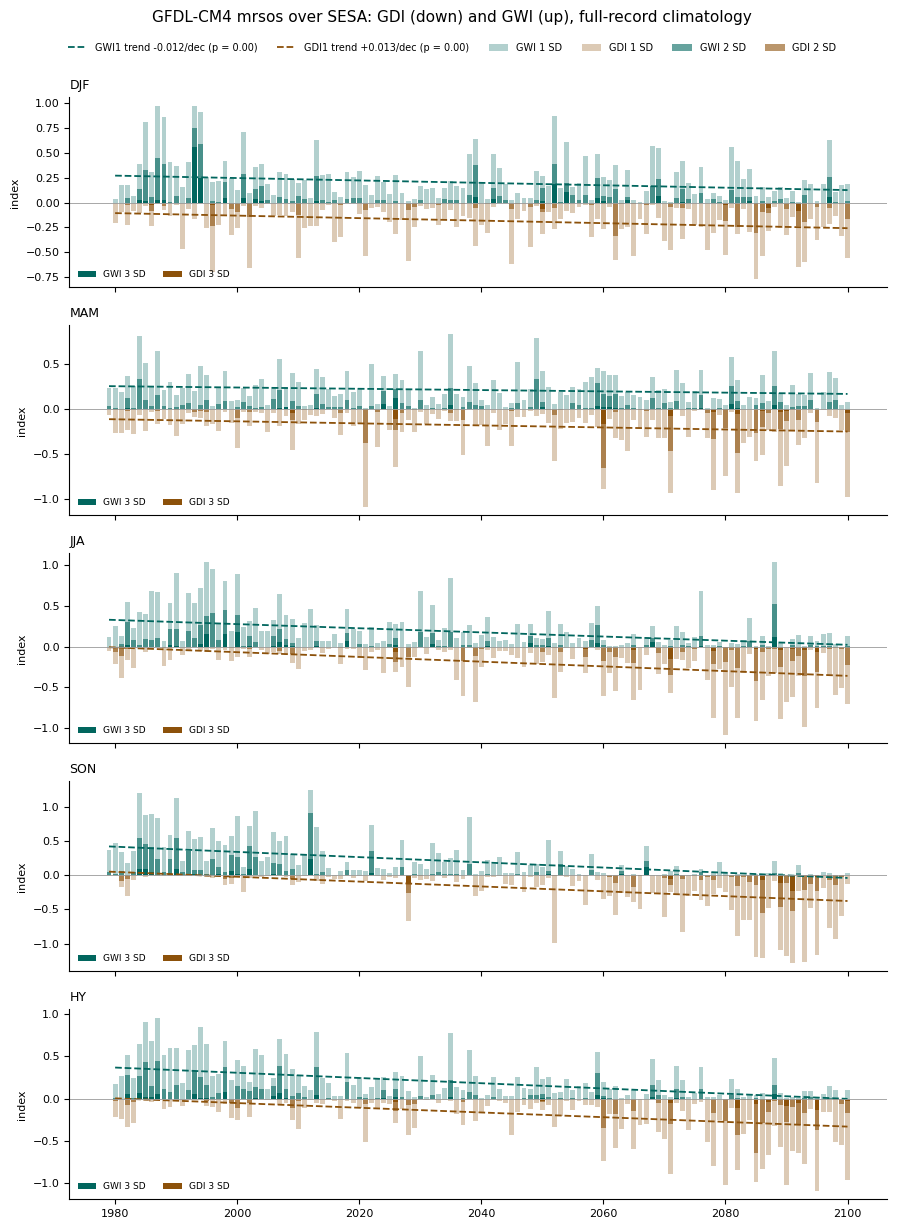

In [13]:
C_DRY, C_WET = "#8c510a", "#01665e"
LEVEL_ALPHA = {1: 0.30, 2: 0.60, 3: 1.0}

fig, axes = plt.subplots(len(GDI_PERIODS), 1, figsize=(9, 2.4 * len(GDI_PERIODS)), sharex=True)
for ax, p in zip(np.atleast_1d(axes), GDI_PERIODS):
    ds = gdgw[p]
    t = ds["year"].values
    for L in GDI_LEVELS:                      # level 1 >= level 2 >= level 3, so draw 1 first
        ax.bar(t, ds[f"GWI{L}"], color=C_WET, alpha=LEVEL_ALPHA[L], width=0.8, linewidth=0, label=f"GWI {L} SD")
        ax.bar(t, -ds[f"GDI{L}"], color=C_DRY, alpha=LEVEL_ALPHA[L], width=0.8, linewidth=0, label=f"GDI {L} SD")
    for name, sign, col in [("GWI1", 1, C_WET), ("GDI1", -1, C_DRY)]:
        v = ds[name].values
        s_, p_ = sen_mk(t, v)
        fit = np.median(v - s_[0] * t) + s_[0] * t
        ax.plot(t, sign * fit, color=col, lw=1.3, ls="--",
                label=f"{name} trend {s_[0] * 10:+.3f}/dec (p = {p_[0]:.2f})")
    ax.axhline(0, color="#999999", lw=0.6)
    ax.set_title(f"{p}", fontsize=9, loc="left")
    ax.set_ylabel("index", fontsize=8)
    ax.tick_params(labelsize=8)
    ax.spines[["top", "right"]].set_visible(False)
axes = np.atleast_1d(axes)
for ax in axes:                                   # trend lines: per panel
    h, l = ax.get_legend_handles_labels()
    ax.legend(h[6:], l[6:], fontsize=6.5, frameon=False, loc="lower left", ncol=2)
handles, labels = axes[0].get_legend_handles_labels()   # bars: one shared legend
fig.legend(handles[:6], labels[:6], fontsize=7, frameon=False, ncol=6, loc="upper center", bbox_to_anchor=(0.5, 1.0))
fig.suptitle(f"{MODEL} {VAR} over SESA: GDI (down) and GWI (up), full-record climatology", fontsize=11, y=1.02)
fig.tight_layout()
fig.savefig(os.path.join(FIG_DIR, f"{MODEL}_sesa_{VAR}_gdi_gwi.png"), dpi=200, bbox_inches="tight")
plt.show()

## Reversal test on the SESA box mean
Slopes are in standard deviations per decade. `p_break` < 0.05 means a two-segment trend fits significantly better than one straight line, even after allowing for the breakpoint search and year-to-year persistence.

In [14]:
results = {}
for s in SEASONS:
    y = box[s]
    results[s] = reversal_test(y["year"].values, y.values)

cols = ["reversal", "break_year", "break_ci", "pre_slope", "pre_ci", "post_slope", "post_ci",
        "p_break", "frac_boot_same_reversal", "sen_full", "p_full", "sen_pre", "p_pre", "sen_post", "p_post", "ar1"]
table = pd.DataFrame({s: {c: r[c] for c in cols} for s, r in results.items()}).T
table.to_csv(os.path.join(OUT_DIR, f"sesa_{MODEL}_{VAR}_reversal_box.csv"))
table

,reversal,break_year,break_ci,pre_slope,pre_ci,post_slope,post_ci,p_break,frac_boot_same_reversal,sen_full,p_full,sen_pre,p_pre,sen_post,p_post,ar1
ANN,wet→dry,1988,"[1988, 2084]",1.822797,"[-0.398, 3.346]",-0.391139,"[-0.832, -0.194]",0.066933,0.843,-0.363103,0.0,4.044781,0.117851,-0.383713,0.0,0.0
DJF,no sign change,2010,"[1989, 2091]",-0.212113,"[-1.382, 0.485]",-0.06864,"[-0.903, 0.951]",0.878122,0.629,-0.086089,0.00072,-0.225445,0.186756,-0.067287,0.068865,0.070987
MAM,no sign change,2049,"[1988, 2091]",-0.034599,"[-1.179, 1.413]",-0.254628,"[-2.007, 0.626]",0.531469,0.454,-0.115713,0.003825,-0.037697,0.612179,-0.341414,0.126767,0.0
JJA,wet→dry,1990,"[1988, 2084]",1.332614,"[-0.269, 2.86]",-0.30546,"[-0.879, -0.229]",0.048951,0.889,-0.277604,0.0,2.423261,0.086768,-0.318894,0.0,0.0
SON,wet→dry,1988,"[1988, 2090]",1.477748,"[-0.481, 2.858]",-0.487522,"[-1.144, -0.105]",0.061938,0.839,-0.461281,0.0,2.40746,0.251452,-0.482408,0.0,0.0


## Figure: box-mean series with single-line and hinge fits

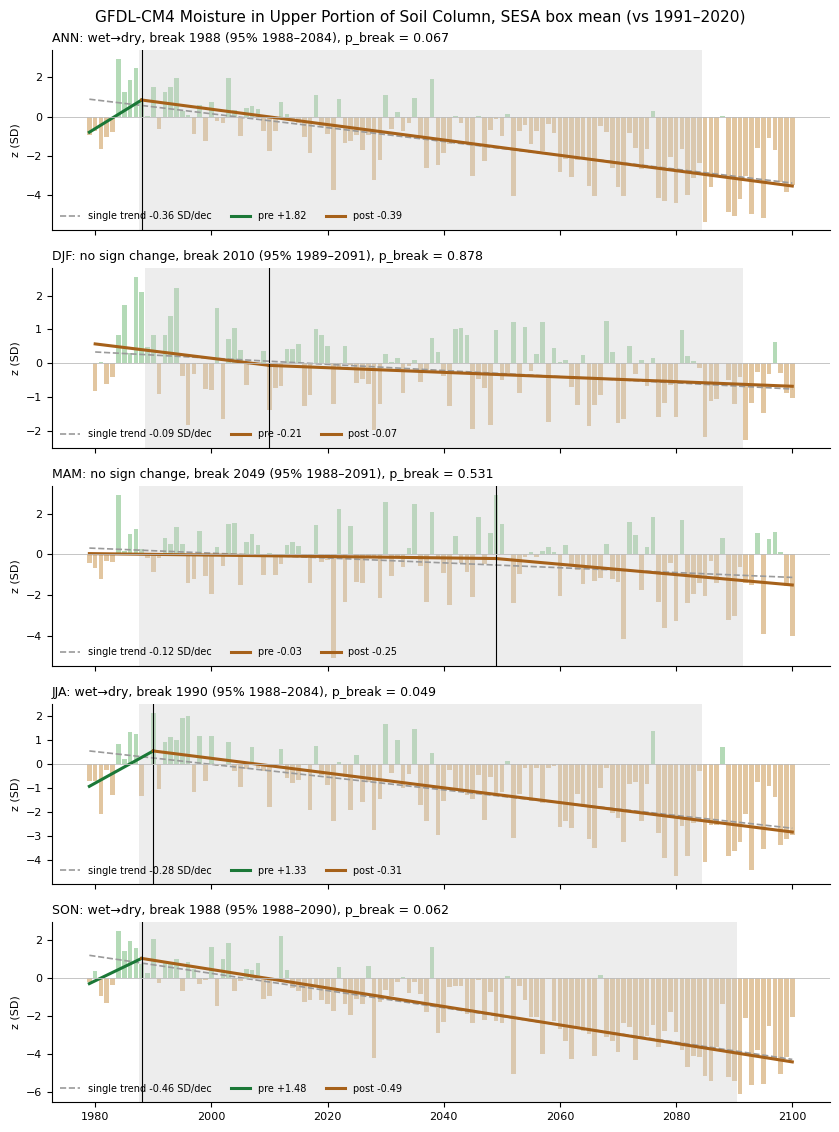

In [15]:
C_OBS, C_LIN, C_PRE, C_POST = "#333333", "#9a9a9a", "#1b7837", "#a6611a"   # green = wetting, brown = drying

fig, axes = plt.subplots(len(SEASONS), 1, figsize=(8.5, 2.3 * len(SEASONS)), sharex=True)
for ax, s in zip(np.atleast_1d(axes), SEASONS):
    y, r = box[s], results[s]
    t = y["year"].values.astype(float)
    f = r["_fit"]
    ax.bar(t, y.values, color=np.where(y.values >= 0, "#5aae61", "#bf812d"), width=0.8, alpha=0.45, linewidth=0)
    ax.plot(t, np.polyval(r["_lin"], t), color=C_LIN, lw=1.2, ls="--", label=f"single trend {r['sen_full']:+.2f} SD/dec")
    yh = f["pre"] * (t - t.mean()) + (f["post"] - f["pre"]) * np.maximum(t - f["tb"], 0)
    yh = yh + (y.values - yh).mean()
    pre, post = t <= f["tb"], t >= f["tb"]
    ax.plot(t[pre], yh[pre], color=C_PRE if f["pre"] > 0 else C_POST, lw=2.2, label=f"pre {r['pre_slope']:+.2f}")
    ax.plot(t[post], yh[post], color=C_POST if f["post"] < 0 else C_PRE, lw=2.2, label=f"post {r['post_slope']:+.2f}")
    lo, hi = r["break_ci"]
    ax.axvspan(lo - 0.5, hi + 0.5, color="#cccccc", alpha=0.35, linewidth=0)
    ax.axvline(f["tb"], color="k", lw=0.8)
    ax.axhline(0, color="#bbbbbb", lw=0.6)
    ax.set_title(f"{s}: {r['reversal']}, break {r['break_year']} (95% {lo}–{hi}), p_break = {r['p_break']:.3f}",
                 fontsize=9, loc="left")
    ax.set_ylabel("z (SD)", fontsize=8)
    ax.tick_params(labelsize=8)
    ax.spines[["top", "right"]].set_visible(False)
    ax.legend(fontsize=7, frameon=False, ncol=3, loc="lower left")
fig.suptitle(f"{MODEL} {sm.attrs['long_name']}, SESA box mean (vs 1991–2020)", fontsize=11)
fig.tight_layout()
fig.savefig(os.path.join(FIG_DIR, f"{MODEL}_sesa_{VAR}_hinge_fits.png"), dpi=200)
plt.show()

## Figure: trend triangle
Sen slope for every window of at least 10 years (x = start, y = end). A reversal shows up as wetting colours for early windows and drying colours for late ones; dots mark Mann-Kendall p < 0.05.

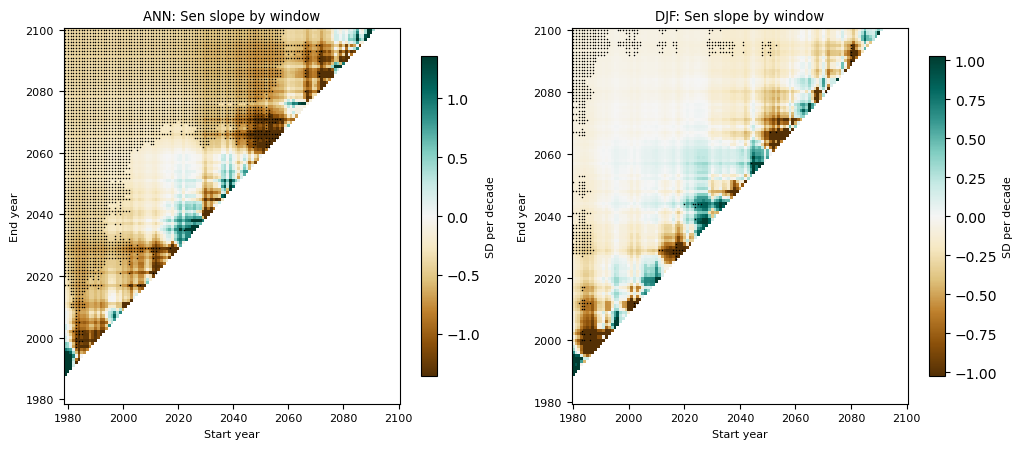

In [16]:
def trend_triangle(y, min_len=10):
    yrs = y["year"].values
    v = y.values
    n = len(yrs)
    S = np.full((n, n), np.nan)
    P = np.full((n, n), np.nan)
    for a in range(n):
        for b in range(a + min_len - 1, n):
            s_, p_ = sen_mk(yrs[a:b + 1], v[a:b + 1])
            S[b, a], P[b, a] = s_[0] * 10, p_[0]
    return yrs, S, P


tri_seasons = ["ANN", "DJF"]
fig, axes = plt.subplots(1, len(tri_seasons), figsize=(5.2 * len(tri_seasons), 4.6), squeeze=False)
for ax, s in zip(axes[0], tri_seasons):
    yrs, S, P = trend_triangle(box[s])
    vmax = np.nanpercentile(np.abs(S), 97)
    pc = ax.pcolormesh(yrs, yrs, S, cmap="BrBG", vmin=-vmax, vmax=vmax, shading="nearest")
    jj, ii = np.where(P < ALPHA)
    ax.scatter(yrs[ii], yrs[jj], s=1.2, c="k", linewidths=0)
    ax.set_xlabel("Start year", fontsize=8)
    ax.set_ylabel("End year", fontsize=8)
    ax.set_title(f"{s}: Sen slope by window", fontsize=9.5)
    ax.tick_params(labelsize=8)
    cb = fig.colorbar(pc, ax=ax, shrink=0.85)
    cb.set_label("SD per decade", fontsize=8)
fig.tight_layout()
fig.savefig(os.path.join(FIG_DIR, f"{MODEL}_sesa_{VAR}_trend_triangle.png"), dpi=200)
plt.show()

## Gridded analysis
Each cell gets z-scores and the hinge fit. **Fixed break:** slopes before and after the box-mean breakpoint for `MAP_SEASON` (Sen + MK per segment). **Free break:** each cell's own best breakpoint year (no significance test per cell; the Monte Carlo is run only for the box mean).

In [17]:
g = standardise(seasonal(sm, MAP_SEASON))
g = g.where(g.notnull().sum("year") >= 0.8 * g.sizes["year"])          # mostly-complete land cells
yrs = g["year"].values.astype(float)
Y = g.transpose("year", "lat", "lon").values.reshape(len(yrs), -1)
valid = np.isfinite(Y).all(0)

tb_box = results[MAP_SEASON]["break_year"]
pre_m, post_m = yrs <= tb_box, yrs >= tb_box

shape = (g.sizes["lat"], g.sizes["lon"])
def empty():
    return np.full(Y.shape[1], np.nan)

s_pre, p_pre, s_post, p_post, tb_cell = empty(), empty(), empty(), empty(), empty()
a, b = sen_mk(yrs[pre_m], Y[pre_m][:, valid]);  s_pre[valid], p_pre[valid] = a * 10, b
a, b = sen_mk(yrs[post_m], Y[post_m][:, valid]); s_post[valid], p_post[valid] = a * 10, b
hf = hinge_fit(yrs, Y[:, valid])
tb_cell[valid] = np.where(np.sign(hf["pre"]) != np.sign(hf["post"]), hf["tb"], np.nan)  # only where the sign flips

# reversal class: 2 = wet→dry, -2 = dry→wet (both segments significant); ±1 = sign flip, not both significant; 0 = none
sig = (p_pre < ALPHA) & (p_post < ALPHA)
cls = np.where(valid, 0.0, np.nan)
cls[(s_pre > 0) & (s_post < 0)] = 1
cls[(s_pre < 0) & (s_post > 0)] = -1
cls[(s_pre > 0) & (s_post < 0) & sig] = 2
cls[(s_pre < 0) & (s_post > 0) & sig] = -2

coords = dict(lat=g["lat"], lon=g["lon"])
maps = xr.Dataset({k: (("lat", "lon"), v.reshape(shape)) for k, v in dict(
    slope_pre=s_pre, p_pre=p_pre, slope_post=s_post, p_post=p_post, reversal_class=cls, break_year_cell=tb_cell).items()},
    coords=coords)
maps.attrs.update(season=MAP_SEASON, break_year_box=tb_box, units_slope="SD per decade")
maps.to_netcdf(os.path.join(OUT_DIR, f"sesa_{MODEL}_{VAR}_reversal_maps_{MAP_SEASON}.nc"))
print(f"break year (box, {MAP_SEASON}) = {tb_box}; cells: {int(valid.sum())}")

break year (box, ANN) = 1988; cells: 1452


## Figure: maps (Robinson)

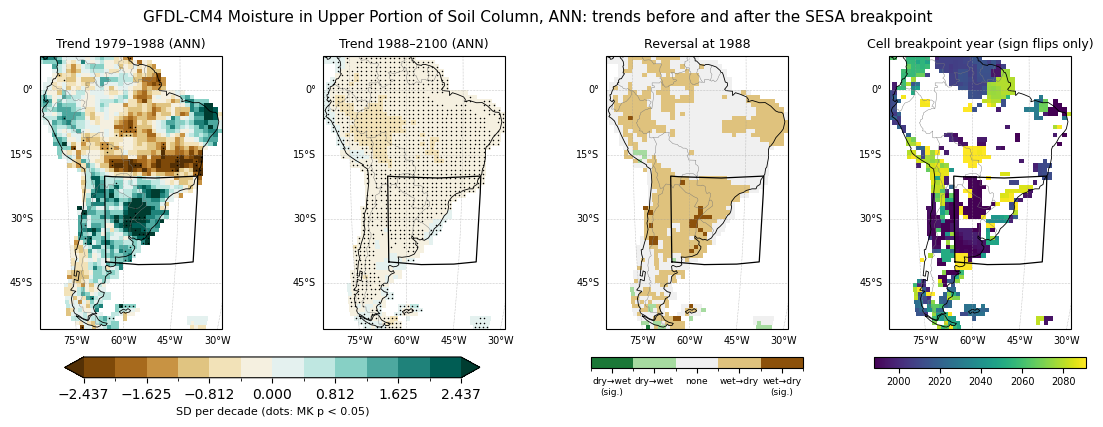

In [18]:
def map_ax(fig, pos):
    ax = fig.add_subplot(*pos, projection=ccrs.Robinson(central_longitude=-60))
    ax.set_extent(MAP_EXTENT, crs=ccrs.PlateCarree())
    ax.add_feature(cfeature.COASTLINE, linewidth=0.6)
    ax.add_feature(cfeature.BORDERS, linewidth=0.3, edgecolor="#777777")
    gl = ax.gridlines(crs=ccrs.PlateCarree(), draw_labels=True, linewidth=0.4, color="#999999", linestyle=":",
                      xlocs=range(-90, -20, 15), ylocs=range(-60, 20, 15))
    gl.top_labels = gl.right_labels = False
    gl.xlabel_style = gl.ylabel_style = {"size": 7}
    (la0, la1), (lo0, lo1) = REGION["lat"], REGION["lon"]
    ax.plot([lo0, lo1, lo1, lo0, lo0], [la0, la0, la1, la1, la0], color="k", lw=0.9, transform=ccrs.Geodetic())
    return ax


def stipple(ax, mask):
    yy, xx = np.meshgrid(maps["lat"].values, maps["lon"].values, indexing="ij")
    m = np.asarray(mask, bool)
    step = max(1, int(round(0.75 / float(np.abs(np.diff(maps["lat"].values)).mean()))))   # thin dots on fine grids
    thin = np.zeros_like(m)
    thin[::step, ::step] = True
    ax.scatter(xx[m & thin], yy[m & thin], s=1.2, c="k", linewidths=0, transform=ccrs.PlateCarree())



y0, y1 = int(yrs.min()), int(yrs.max())
fig = plt.figure(figsize=(14, 4.6))
vmax = float(np.nanpercentile(np.abs(np.r_[s_pre, s_post]), 97))
norm = mcolors.BoundaryNorm(np.linspace(-vmax, vmax, 13), 256, extend="both")

for k, (var, pv, title) in enumerate([("slope_pre", "p_pre", f"{y0}–{tb_box}"), ("slope_post", "p_post", f"{tb_box}–{y1}")]):
    ax = map_ax(fig, (1, 4, k + 1))
    pc = ax.pcolormesh(maps["lon"], maps["lat"], maps[var], cmap="BrBG", norm=norm, shading="nearest",
                       transform=ccrs.PlateCarree())
    stipple(ax, maps[pv] < ALPHA)
    ax.set_title(f"Trend {title} ({MAP_SEASON})", fontsize=9)
cb = fig.colorbar(pc, ax=fig.axes[:2], orientation="horizontal", shrink=0.8, pad=0.08)
cb.set_label("SD per decade (dots: MK p < 0.05)", fontsize=8)

ax = map_ax(fig, (1, 4, 3))
cmap = mcolors.ListedColormap(["#1b7837", "#a6dba0", "#f0f0f0", "#dfc27d", "#8c510a"])
pc3 = ax.pcolormesh(maps["lon"], maps["lat"], maps["reversal_class"], cmap=cmap,
                    norm=mcolors.BoundaryNorm([-2.5, -1.5, -0.5, 0.5, 1.5, 2.5], 5), shading="nearest",
                    transform=ccrs.PlateCarree())
ax.set_title(f"Reversal at {tb_box}", fontsize=9)
cb3 = fig.colorbar(pc3, ax=ax, orientation="horizontal", shrink=0.9, pad=0.08, ticks=[-2, -1, 0, 1, 2])
cb3.ax.set_xticklabels(["dry→wet\n(sig.)", "dry→wet", "none", "wet→dry", "wet→dry\n(sig.)"], fontsize=6.5)

ax = map_ax(fig, (1, 4, 4))
pc4 = ax.pcolormesh(maps["lon"], maps["lat"], maps["break_year_cell"], cmap="viridis", shading="nearest",
                    vmin=yrs[MIN_SEG - 1], vmax=yrs[-MIN_SEG], transform=ccrs.PlateCarree())
ax.set_title("Cell breakpoint year (sign flips only)", fontsize=9)
cb4 = fig.colorbar(pc4, ax=ax, orientation="horizontal", shrink=0.9, pad=0.08)
cb4.ax.tick_params(labelsize=7)

fig.suptitle(f"{MODEL} {sm.attrs['long_name']}, {MAP_SEASON}: trends before and after the SESA breakpoint", fontsize=11)
fig.savefig(os.path.join(FIG_DIR, f"{MODEL}_sesa_{VAR}_reversal_maps_{MAP_SEASON}.png"), dpi=200, bbox_inches="tight")
plt.show()